# Bloc 6 — Données textuelles (cours 6)
**Fichier** : `clinical_notes` (30 notes cliniques, colonnes `title` et `text`). C'est le seul fichier texte de la partie clinique.

Plan :
1. Vérifier l'**encodage** (UTF-8) et la **langue**.
2. **Dédoublonner** les phrases répétées dans une même note (sinon les fréquences sont faussées).
3. **Pré-traitement** : minuscules, ponctuation, espaces, tokenisation, stopwords (`nltk`) + stopwords du domaine, PoS tagging, lemmatisation.
4. **Bag of words** et nuage de mots (avec leurs limites), **n-grams** de plusieurs tailles.
5. **TF-IDF** par document et par sous-groupe (`document_type`, `confidentiality_class`).
6. **Réutiliser les blocs 2 et 3** sur les vecteurs : similarité, anomalies, clustering.
7. **Topic modeling** (LSA et LDA), fragile avec 30 notes.
8. Relier chaque terme repéré à un **passage lisible** (concordancier), pour le bloc 7.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 120)
chemin = 'cleaned/'
notes = pd.read_csv(chemin + 'clinical_notes_cleaned.csv', parse_dates=['document_date'])
print(notes.shape)
notes.groupby(['document_type', 'confidentiality_class']).size().unstack(fill_value=0)

(30, 10)


confidentiality_class,confidential,restricted,standard
document_type,,,
clinical_summary,3,0,3
follow_up_note,2,1,3
imaging_report,2,1,3
occupational_assessment,3,2,1
specialist_consultation,1,3,2


### Outils `nltk`
On utilise `nltk` pour les stopwords, la tokenisation, le PoS tagging et la lemmatisation. Les ressources sont téléchargées au premier lancement. Si `nltk` ou ses ressources ne sont pas disponibles (pas d'internet), la cellule se replie sur des équivalents simples (stopwords de `scikit-learn`, tokenisation par expression régulière, pas de lemmatisation) et l'indique : le reste du notebook tourne quand même.

In [2]:
try:
    import nltk
    for ressource in ['stopwords', 'punkt', 'punkt_tab', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'wordnet', 'omw-1.4']:
        nltk.download(ressource, quiet=True)
    from nltk.corpus import stopwords, wordnet
    from nltk.stem import WordNetLemmatizer
    STOP_EN = set(stopwords.words('english'))
    STOP_FR = set(stopwords.words('french'))
    tokeniser = nltk.word_tokenize
    tokeniser('test phrase.'); nltk.pos_tag(['test']); WordNetLemmatizer().lemmatize('tests')   # vérifie que les ressources sont là
    lemmatiseur = WordNetLemmatizer()
    def pos_tag(tokens):
        return nltk.pos_tag(tokens)
    def lemmatiser(mot, tag):
        wn = {'J': wordnet.ADJ, 'V': wordnet.VERB, 'N': wordnet.NOUN, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)
        return lemmatiseur.lemmatize(mot, wn)
    NLTK_OK = True
except Exception as err:
    print(f'nltk indisponible ({type(err).__name__}) : repli sur des outils simples')
    STOP_EN = set(ENGLISH_STOP_WORDS)
    STOP_FR = {'le', 'la', 'les', 'de', 'des', 'du', 'et', 'en', 'un', 'une', 'est', 'que', 'qui', 'dans', 'pour', 'pas', 'sur', 'au', 'par'}
    tokeniser = lambda t: re.findall(r"[a-z]+(?:-[a-z]+)*", t)
    pos_tag = lambda tokens: [(t, 'NN') for t in tokens]
    lemmatiser = lambda mot, tag: mot
    NLTK_OK = False
print('nltk utilisé :', NLTK_OK, '| stopwords anglais :', len(STOP_EN))

nltk indisponible (ModuleNotFoundError) : repli sur des outils simples
nltk utilisé : False | stopwords anglais : 318


## 1. Encodage et langue

In [3]:
brut = open(chemin + 'clinical_notes_cleaned.csv', 'rb').read()
brut.decode('utf-8')   # lève une erreur si le fichier n'est pas en UTF-8 valide
non_ascii = Counter(c for c in brut.decode('utf-8') if ord(c) > 127)
print('UTF-8 valide. Caractères non ASCII :', dict(non_ascii) if non_ascii else 'aucun')

mots = re.findall(r'[a-z]+', ' '.join(notes.text).lower())
print(f'Part de mots-outils anglais : {np.mean([m in STOP_EN for m in mots]):.1%} ; français : {np.mean([m in STOP_FR for m in mots]):.1%}')

UTF-8 valide. Caractères non ASCII : aucun
Part de mots-outils anglais : 33.0% ; français : 0.0%


Le fichier est en **UTF-8** valide, et les textes sont en **anglais** (environ un tiers des mots sont des mots-outils anglais, presque aucun mot-outil français). On utilise donc les stopwords anglais.

## 2. Dédoublonnage des phrases
Plusieurs notes répètent mot pour mot une ou plusieurs phrases (copier-coller de modèle). On découpe en phrases et on garde la **première occurrence** de chaque phrase dans une note.

In [4]:
def phrases(texte):
    return [p.strip() for p in re.split(r'(?<=[.!?])\s+', texte) if p.strip()]

notes['phrases'] = notes.text.apply(phrases)
notes['phrases_uniques'] = notes.phrases.apply(lambda l: list(dict.fromkeys(l)))
notes['nb_doublons'] = notes.phrases.str.len() - notes.phrases_uniques.str.len()
notes['texte_dedup'] = notes.phrases_uniques.apply(' '.join)
print(f"{notes.nb_doublons.sum()} phrases dupliquées supprimées, dans {(notes.nb_doublons > 0).sum()} notes sur 30")
notes.groupby('document_type').nb_doublons.agg(['sum', 'max'])

42 phrases dupliquées supprimées, dans 16 notes sur 30


,sum,max
document_type,,
clinical_summary,6,1
follow_up_note,0,0
imaging_report,0,0
occupational_assessment,12,2
specialist_consultation,24,6


42 phrases en double, toutes dans des notes « modèles » (`clinical_summary`, `occupational_assessment`, `specialist_consultation`). Sans ce nettoyage, des phrases génériques comme *« The record concerns ... »* compteraient deux fois et domineraient les fréquences.

### 2.1 Phrases « modèles » communes à beaucoup de notes
Au-delà des doublons internes, beaucoup de phrases se retrouvent dans plusieurs notes (gabarit de rédaction). On compte, pour chaque phrase, le nombre de notes qui la contiennent.

In [5]:
freq_phrase = Counter(p for l in notes.phrases_uniques for p in set(l))
SEUIL_MODELE = 5   # une phrase présente dans au moins 5 notes est considérée comme du gabarit
gabarit = {p for p, k in freq_phrase.items() if k >= SEUIL_MODELE}
print(len(gabarit), 'phrases présentes dans au moins', SEUIL_MODELE, 'notes, par exemple :')
for p, k in sorted(((p, freq_phrase[p]) for p in gabarit), key=lambda x: -x[1])[:5]:
    print(f'  [{k:2d} notes] {p}')
notes['texte_specifique'] = notes.phrases_uniques.apply(lambda l: ' '.join(p for p in l if p not in gabarit))
notes['mots_specifiques'] = notes.texte_specifique.str.split().str.len()
notes[['document_id', 'document_type', 'confidentiality_class', 'patient_number', 'mots_specifiques']].sort_values('mots_specifiques', ascending=False).head(8)

27 phrases présentes dans au moins 5 notes, par exemple :
  [26 notes] The assessment distinguishes reproducible findings from artefact and recommends correlation rather than categorical interpretation.
  [26 notes] Measurements were reviewed against prior visits, device quality, medication history, and ordinary technical explanations.
  [26 notes] No acute deterioration was identified, and follow-up remains proportionate to the recorded functional risk.
  [21 notes] Source-local patient, encounter, facility, and professional references were retained for audit.
  [16 notes] The note should not be read as a complete explanation of the patient's biology or identity.


,document_id,document_type,confidentiality_class,patient_number,mots_specifiques
1,CLN-510055,specialist_consultation,restricted,PAT-31115,267
2,CLN-510025,specialist_consultation,restricted,PAT-31065,256
0,CLN-510027,imaging_report,restricted,PAT-31065,212
3,CLN-510064,follow_up_note,confidential,PAT-31012,174
15,CLN-510039,specialist_consultation,restricted,PAT-31103,115
16,CLN-510106,specialist_consultation,standard,PAT-31056,97
18,CLN-510092,specialist_consultation,standard,PAT-31219,97
17,CLN-510102,specialist_consultation,confidential,PAT-31079,97


Une fois le gabarit retiré, la plupart des notes se réduisent à **23-31 mots** (le motif de consultation et deux phrases d'en-tête). **Quatre notes** gardent plus de 170 mots spécifiques : CLN-510055, CLN-510025, CLN-510027 et CLN-510064. Ce sont des textes rédigés, pas des gabarits. Trois notes intermédiaires (≈ 100 mots) ont un gabarit propre partagé par 4 notes `specialist_consultation`, et CLN-510126 (49 mots) contient une phrase finale ajoutée au gabarit d'imagerie.

## 3. Pré-traitement
Minuscules → suppression de la ponctuation (on garde les tirets internes : `peripheral-pulse` reste un mot) → espaces normalisés → tokenisation → PoS tagging → lemmatisation selon la catégorie grammaticale → suppression des stopwords anglais **et des stopwords du domaine**.

**Stopwords du domaine** : mots présents dans plus de 80 % des notes (vocabulaire du gabarit, ils ne distinguent aucune note), plus quelques mots de structure des comptes rendus (`indication`, `impression`, `plan`...).

In [6]:
def normaliser(texte):
    texte = texte.lower()
    texte = re.sub(r'[^a-z0-9\s-]', ' ', texte)        # ponctuation
    texte = re.sub(r'(?<![a-z])-|-(?![a-z])', ' ', texte)  # tirets isolés
    return re.sub(r'\s+', ' ', texte).strip()            # espaces

def lemmes(texte):
    tokens = [t for t in tokeniser(normaliser(texte)) if re.fullmatch(r'[a-z][a-z-]+', t)]
    return [lemmatiser(t, tag) for t, tag in pos_tag(tokens)]

notes['lemmes'] = notes.texte_dedup.apply(lemmes)

df_lemmes = Counter(l for doc in notes.lemmes for l in set(doc))
STOP_DOMAINE = {l for l, k in df_lemmes.items() if k / len(notes) > 0.8} | {
    'indication', 'technique', 'finding', 'impression', 'recommendation', 'plan', 'assessment', 'history',
    'reason', 'context', 'note', 'record', 'patient', 'pat', 'enc', 'encounter'}
STOP = STOP_EN | STOP_DOMAINE
print('Stopwords du domaine (> 80 % des notes, hors stopwords anglais) :', sorted(l for l, k in df_lemmes.items() if k / len(notes) > 0.8 and l not in STOP_EN))

notes['tokens'] = notes.lemmes.apply(lambda l: [t for t in l if t not in STOP and len(t) > 2])
notes['texte_pret'] = notes.tokens.apply(' '.join)
print('Exemple de PoS tagging :', pos_tag(tokeniser(normaliser('Two spatially distinct zones of contractile motion are visible.')))[:8])
print('Exemple après pré-traitement :', notes.tokens.iloc[0][:25])

Stopwords du domaine (> 80 % des notes, hors stopwords anglais) : ['acute', 'artefact', 'assessment', 'available', 'categorical', 'clinical', 'concerns', 'correlation', 'deterioration', 'device', 'distinguishes', 'explanations', 'findings', 'follow-up', 'functional', 'history', 'identified', 'interpretation', 'limited', 'measurements', 'medication', 'observations', 'ordinary', 'patient', 'prior', 'proportionate', 'quality', 'recommends', 'record', 'recorded', 'remains', 'reproducible', 'reviewed', 'risk', 'team', 'technical', 'visits']
Exemple de PoS tagging : [('two', 'NN'), ('spatially', 'NN'), ('distinct', 'NN'), ('zones', 'NN'), ('of', 'NN'), ('contractile', 'NN'), ('motion', 'NN'), ('are', 'NN')]
Exemple après pré-traitement : ['review', 'recurrent', 'discordance', 'peripheral', 'pulse', 'apical', 'recordings', 'restricted', 'comparison', 'rhythm', 'study', 'targeted', 'thoracic', 'ultrasound', 'synchronized', 'surface', 'recording', 'performed', 'acoustic', 'windows', 'acceptable

## 4. Bag of words, nuage de mots, n-grams

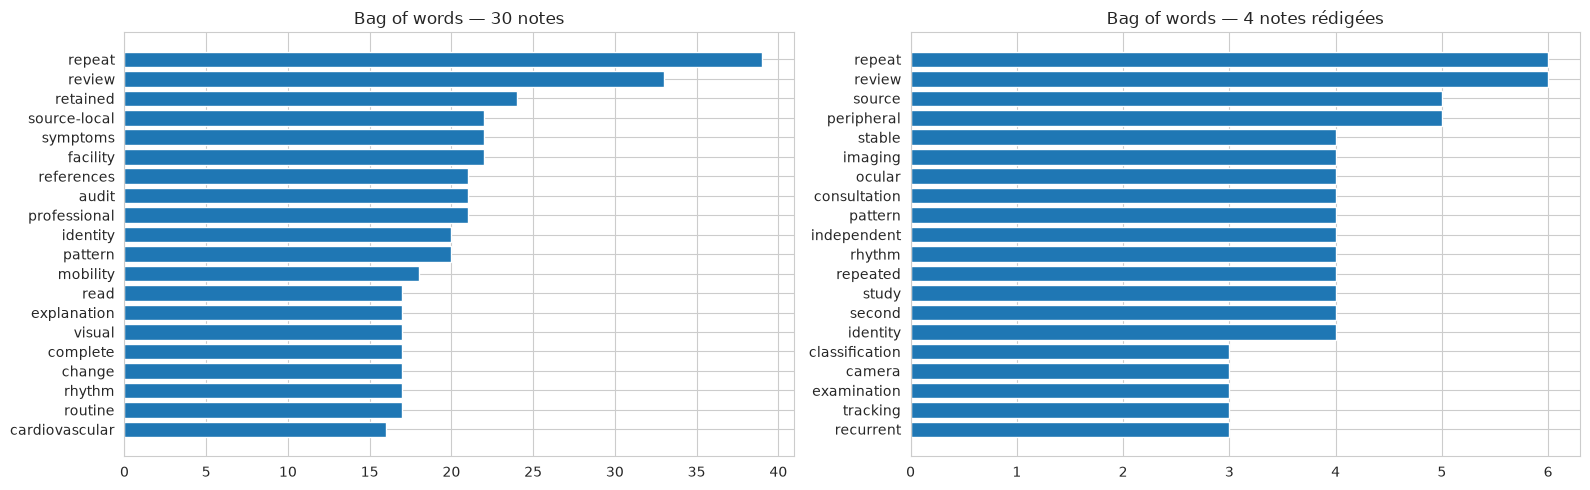

repeat            39
review            33
retained          24
facility          22
source-local      22
symptoms          22
professional      21
references        21
audit             21
pattern           20
identity          20
mobility          18
rhythm            17
routine           17
change            17
complete          17
read              17
visual            17
explanation       17
biology           16
cardiovascular    16
tracking          15
pulse             14
acquisition       14
occupational      14
dtype: int64

In [7]:
bow = Counter(t for doc in notes.tokens for t in doc)
top_bow = pd.Series(dict(bow.most_common(25)))

def nuage(freqs, titre, ax):
    try:
        from wordcloud import WordCloud
        wc = WordCloud(width=800, height=400, background_color='white', random_state=0).generate_from_frequencies(freqs)
        ax.imshow(wc, interpolation='bilinear'); ax.axis('off')
    except ImportError:   # wordcloud non installé : barplot des fréquences à la place
        s = pd.Series(freqs).sort_values().tail(20)
        ax.barh(s.index, s.values)
    ax.set_title(titre)

uniques = ['CLN-510055', 'CLN-510025', 'CLN-510027', 'CLN-510064']
bow_rediges = Counter(t for doc in notes[notes.document_id.isin(uniques)].tokens for t in doc)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
nuage(dict(bow.most_common(80)), 'Bag of words — 30 notes', axes[0])
nuage(dict(bow_rediges.most_common(80)), 'Bag of words — 4 notes rédigées', axes[1])
plt.tight_layout(); plt.show()
top_bow

**Lecture et limites du bag of words**
- Sur les 30 notes, les mots les plus fréquents sont ceux du **gabarit** (`repeat`, `review`, `retain`, `facility`, `source-local`, `reference`, `audit`...) : la fréquence brute récompense la répétition, pas l'information.
- Sur les 4 notes rédigées, le vocabulaire change : `source`, `second`, `independent`, `ocular`, `identity`, `peripheral`, `apical`, `contractile`, `camera`...
- **Limites** : le bag of words ignore l'ordre et le contexte (*« dual cardiac structures was ... rejected »* et *« dual cardiac structures are considered »* donnent les mêmes mots), il est **sensible à la casse** et à la forme des mots si on ne normalise pas (`Apical` ≠ `apical`, `sources` ≠ `source` sans lemmatisation), et il dépend fortement de la liste de stopwords.

In [8]:
def top_ngrams(textes, n, k=12):
    cv = CountVectorizer(ngram_range=(n, n), token_pattern=r'[a-z][a-z-]+')
    X = cv.fit_transform(textes)
    return pd.Series(np.asarray(X.sum(0)).ravel(), index=cv.get_feature_names_out()).sort_values(ascending=False).head(k)

pd.concat({f'{n}-grams (30 notes)': top_ngrams(notes.texte_pret, n).reset_index().apply(lambda r: f'{r.iloc[0]} ({r.iloc[1]})', axis=1)
           for n in (1, 2, 3)} | {f'{n}-grams (4 notes rédigées)': top_ngrams(notes[notes.document_id.isin(uniques)].texte_pret, n).reset_index().apply(lambda r: f'{r.iloc[0]} ({r.iloc[1]})', axis=1)
           for n in (2, 3)}, axis=1)

,1-grams (30 notes),2-grams (30 notes),3-grams (30 notes),2-grams (4 notes rédigées),3-grams (4 notes rédigées)
0,repeat (39),professional references (21),references retained audit (21),peripheral pulse (3),identity biological classification (2)
1,review (33),facility professional (21),professional references retained (21),partly independent (3),ocular tracking atypical (2)
2,retained (24),source-local facility (21),source-local facility professional (21),ocular tracking (3),referral sequence appointment (1)
3,facility (22),retained audit (21),facility professional references (21),gait ocular (2),referral facility rare (1)
4,symptoms (22),references retained (21),audit read complete (16),tracking atypical (2),reduces does eliminate (1)
5,source-local (22),read complete (16),read complete explanation (16),identity biological (2),reduced did remove (1)
6,references (21),complete explanation (16),retained audit read (16),short intervals (2),recurrent rhythm complexity (1)
7,audit (21),audit read (16),complete explanation biology (16),biological classification (2),recurrent overlap variable (1)
8,professional (21),explanation biology (16),explanation biology identity (16),swaying gait (2),recurrent discordance peripheral (1)
9,identity (20),biology identity (16),post-viral rhythm check (8),lead replacement (2),recur performance preserved (1)


- Les **unigrammes** restent dominés par le gabarit.
- Les **bigrammes et trigrammes** sur tout le corpus retrouvent les formules toutes faites des gabarits (motifs de consultation comme *post-viral rhythm check*, phrases d'audit...).
- Sur les **4 notes rédigées**, les bigrammes font apparaître les expressions qui portent le récit (*peripheral pulse*, *partly independent*, *ocular tracking*, *swaying gait*, *lead replacement*, *biological classification*...). Les trigrammes y deviennent presque tous uniques (fréquence 1 ou 2) : au-delà de 2-3 mots, les n-grams ne servent plus qu'à retrouver des phrases précises.

## 5. TF-IDF par document et par sous-groupe
TF-IDF = fréquence du terme dans le document × log(inverse de la part de documents qui le contiennent). Un terme fréquent partout (gabarit) a un poids faible ; un terme propre à une note ou à un groupe ressort.

In [9]:
tfidf = TfidfVectorizer(token_pattern=r'[a-z][a-z-]+', ngram_range=(1, 2), min_df=1, sublinear_tf=True)
X = tfidf.fit_transform(notes.texte_pret)
vocab = tfidf.get_feature_names_out()

def top_termes(ligne, k=6):
    ligne = np.asarray(ligne.todense()).ravel()
    return ', '.join(vocab[i] for i in ligne.argsort()[::-1][:k] if ligne[i] > 0)

notes['termes_tfidf'] = [top_termes(X[i]) for i in range(X.shape[0])]
notes[['document_id', 'document_type', 'patient_number', 'termes_tfidf']]

,document_id,document_type,patient_number,termes_tfidf
0,CLN-510027,imaging_report,PAT-31065,"contractile, study, source, anatomical, dominant, sources"
1,CLN-510055,specialist_consultation,PAT-31115,"camera, facial, short intervals, images, independently, discrepancy"
2,CLN-510025,specialist_consultation,PAT-31065,"public, consultation, referral, attribute, linkage, historical"
3,CLN-510064,follow_up_note,PAT-31012,"vestibular, gait, ocular, reported fall, stay high, stepping"
4,CLN-510107,clinical_summary,PAT-31115,"occupational fatigue, concerning occupational, fatigue salient, change occupational, occupational, fatigue"
5,CLN-510113,clinical_summary,PAT-31215,"post-viral, post-viral rhythm, check, rhythm check, concerning post-viral, change post-viral"
6,CLN-510009,clinical_summary,PAT-31012,"mobility, mobility salient, concerning mobility, change mobility, mobility source-local, symptoms"
7,CLN-510010,clinical_summary,PAT-31037,"tracking review, change visual, review salient, concerning visual, visual tracking, symptoms"
8,CLN-510087,clinical_summary,PAT-31044,"metabolic, change metabolic, concerning metabolic, metabolic salient, symptoms, metabolic source-local"
9,CLN-510081,clinical_summary,PAT-31074,"pre-travel medical, pre-travel, clearance, medical clearance, medical, change pre-travel"


In [10]:
def tfidf_groupes(col, k=8):
    groupes = notes.groupby(col).texte_pret.apply(' '.join)
    v = TfidfVectorizer(token_pattern=r'[a-z][a-z-]+', ngram_range=(1, 2), sublinear_tf=True)
    M = v.fit_transform(groupes); voc = v.get_feature_names_out()
    return pd.Series({g: ', '.join(voc[np.asarray(M[i].todense()).ravel().argsort()[::-1][:k]]) for i, g in enumerate(groupes.index)})

display(tfidf_groupes('document_type').to_frame('termes caractéristiques (document_type)'))
display(tfidf_groupes('confidentiality_class').to_frame('termes caractéristiques (confidentiality_class)'))

,termes caractéristiques (document_type)
clinical_summary,"symptoms, combined pattern, continue retain, repeat targeted, pressure, pressure oxygen, saturation mobility, satura..."
follow_up_note,"symptoms, material previously, earlier, irregular value, additional restriction, additional, response tolerating, pr..."
imaging_report,"motion, cardiac, recommended, repositioning, effusion, effusion structural, favored, favored recommended"
occupational_assessment,"role, physical, sleep pattern, sleep, duty periods, intermittent, intermittent physical, duty"
specialist_consultation,"examination, does, recommendations, rare, reduced, supports, document, evidence supports"


,termes caractéristiques (confidentiality_class)
confidential,"repeat, mobility, acquisition repeat, references, professional references, retained audit, identity, professional"
restricted,"source, study, repeated, camera, consultation, contractile, mismatch, public"
standard,"repeat, review, post-viral rhythm, check, rhythm check, acquisition repeat, post-viral, symptoms"


**Lecture**
- Par **document** : les notes gabarits ont comme termes caractéristiques leur seul motif (*metabolic*, *pre-travel clearance*, *post-viral rhythm*...), tandis que les 4 notes rédigées ont des termes propres : CLN-510027 (*contractile*, *source*, *dominant*), CLN-510055 (*camera*, *facial*, *discrepancy*), CLN-510025 (*public*, *referral*, *attribute*, *linkage*), CLN-510064 (*vestibular*, *gait*, *ocular*).
- Par **`document_type`** : les termes caractéristiques sont ceux des gabarits (imagerie : *motion*, *contour*, *effusion* ; aptitude : *role*, *duty*, *sleep*). Les 4 notes rédigées sont « noyées » dans leur type : le regroupement par type ne les fait pas ressortir.
- Par **`confidentiality_class`** : c'est ici que le récit apparaît. Les notes `restricted` ont pour termes caractéristiques *source*, *camera*, *contractile*, *mismatch*, *public* ; les notes `standard` et `confidential` n'ont que du vocabulaire de gabarit.

## 6. Réutiliser les blocs 2 et 3 sur les vecteurs TF-IDF
Chaque note est un vecteur TF-IDF. On calcule la **similarité cosinus** entre notes, puis :
- **anomalies** (bloc 3) : une note qui ressemble peu aux autres (similarité moyenne basse) est atypique ; on applique l'IQR et le z-score modifié à cette similarité moyenne ;
- **clustering** (bloc 2) : classification hiérarchique sur la distance cosinus.

Ces vecteurs jouent ici le rôle d'**embeddings** simples. Des embeddings de type BERT seraient plus riches mais demandent un modèle pré-entraîné à télécharger ; avec 30 notes dont 26 gabarits, TF-IDF suffit à séparer les textes (voir la limite en fin de notebook).

Notes atypiques (IQR) : ['CLN-510027', 'CLN-510055', 'CLN-510025', 'CLN-510064']
Notes atypiques (z modifié < -3,5) : ['CLN-510027', 'CLN-510055', 'CLN-510025', 'CLN-510064']


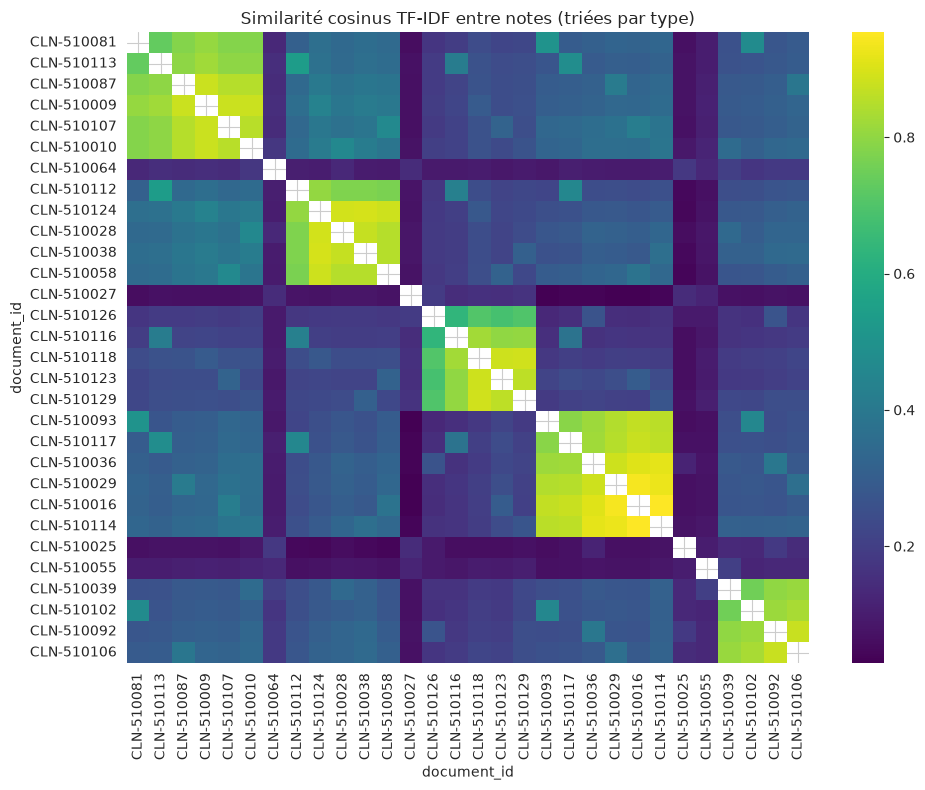

,document_id,document_type,confidentiality_class,sim_moyenne,z_mod
0,CLN-510027,imaging_report,restricted,0.085,-5.780
2,CLN-510025,specialist_consultation,restricted,0.086,-5.769
1,CLN-510055,specialist_consultation,restricted,0.100,-5.457
3,CLN-510064,follow_up_note,confidential,0.126,-4.858
10,CLN-510126,imaging_report,confidential,0.240,-2.307
13,CLN-510116,imaging_report,standard,0.277,-1.490


In [11]:
# Similarité sur le texte dédoublonné complet (gabarit compris) : c'est le gabarit qui rend les notes semblables
Xs = TfidfVectorizer(stop_words='english', sublinear_tf=True).fit_transform(notes.texte_dedup)
S = cosine_similarity(Xs)
np.fill_diagonal(S, np.nan)
notes['sim_moyenne'] = np.nanmean(S, axis=1)

q1, q3 = notes.sim_moyenne.quantile([.25, .75])
med = notes.sim_moyenne.median(); mad = (notes.sim_moyenne - med).abs().median()
notes['iqr_bas'] = notes.sim_moyenne < q1 - 1.5 * (q3 - q1)
notes['z_mod'] = 0.6745 * (notes.sim_moyenne - med) / mad
print('Notes atypiques (IQR) :', notes.loc[notes.iqr_bas, 'document_id'].tolist())
print('Notes atypiques (z modifié < -3,5) :', notes.loc[notes.z_mod < -3.5, 'document_id'].tolist())

ordre = notes.sort_values(['document_type', 'sim_moyenne']).index
plt.figure(figsize=(10, 8))
sns.heatmap(pd.DataFrame(S, index=notes.document_id, columns=notes.document_id).iloc[ordre, ordre], cmap='viridis')
plt.title('Similarité cosinus TF-IDF entre notes (triées par type)'); plt.tight_layout(); plt.show()
notes.sort_values('sim_moyenne')[['document_id', 'document_type', 'confidentiality_class', 'sim_moyenne', 'z_mod']].head(6).round(3)

In [12]:
D = np.clip(1 - cosine_similarity(Xs), 0, None)   # arrondis numériques : pas de distance négative
np.fill_diagonal(D, 0)
sil = {}
for k in range(2, 13):
    lab = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average').fit_predict(D)
    sil[k] = silhouette_score(D, lab, metric='precomputed')
print('Silhouette (cosinus) par k :', {k: round(v, 2) for k, v in sil.items()})
k_opt = max(sil, key=sil.get)
notes['cluster_texte'] = AgglomerativeClustering(n_clusters=k_opt, metric='precomputed', linkage='average').fit_predict(D)
pd.crosstab(notes.document_type, notes.cluster_texte)

Silhouette (cosinus) par k : {2: 0.27, 3: 0.27, 4: 0.25, 5: 0.24, 6: 0.31, 7: 0.37, 8: 0.52, 9: 0.64, 10: 0.59, 11: 0.49, 12: 0.42}


cluster_texte,0,1,2,3,4,5,6,7,8
document_type,,,,,,,,,
clinical_summary,0,0,6,0,0,0,0,0,0
follow_up_note,0,5,0,0,0,0,0,0,1
imaging_report,5,0,0,0,0,0,0,1,0
occupational_assessment,0,0,0,6,0,0,0,0,0
specialist_consultation,0,0,0,0,1,1,4,0,0


**Lecture**
- Les notes gabarits sont très semblables à celles de leur type (blocs clairs sur la carte de similarité). Les **4 notes rédigées** ont la similarité moyenne la plus basse et sont signalées par l'IQR et le z-score modifié : ce sont les **anomalies textuelles** du corpus.
- Le clustering hiérarchique (distance cosinus, liaison moyenne) a sa meilleure silhouette à **k = 9** (≈ 0,64) : 5 clusters correspondent aux 5 gabarits (un par type de document, les 4 `specialist_consultation` gabarits ensemble), et les **4 autres clusters sont des singletons : exactement les 4 notes rédigées**. La structure textuelle est donc celle du générateur, avec 4 exceptions. CLN-510126 (leurre, voir plus bas) reste avec les gabarits d'imagerie.

## 7. Topic modeling (LSA et LDA)
- **LSA** : SVD tronquée de la matrice TF-IDF.
- **LDA** : modèle probabiliste sur les comptes de mots (bag of words).

Avec 30 documents courts dont 26 gabarits, les topics sont **fragiles** : on teste la stabilité de la LDA en changeant la graine aléatoire.

In [13]:
K = 4
svd = TruncatedSVD(n_components=K, random_state=0).fit(X)
print('LSA — variance expliquée :', svd.explained_variance_ratio_.round(3))
for i, comp in enumerate(svd.components_):
    print(f'  LSA topic {i}:', ', '.join(vocab[comp.argsort()[::-1][:8]]))

cv = CountVectorizer(token_pattern=r'[a-z][a-z-]+')
C = cv.fit_transform(notes.texte_pret); voc_c = cv.get_feature_names_out()
topics_par_graine = {}
for graine in [0, 1, 2]:
    lda = LatentDirichletAllocation(n_components=K, random_state=graine, learning_method='batch', max_iter=200).fit(C)
    topics_par_graine[graine] = [set(voc_c[c.argsort()[::-1][:10]]) for c in lda.components_]
    if graine == 0:
        notes['topic_lda'] = lda.transform(C).argmax(1)
        for i, c in enumerate(lda.components_):
            print(f'  LDA topic {i}:', ', '.join(voc_c[c.argsort()[::-1][:8]]))

# stabilité : pour chaque topic de la graine 0, meilleur recouvrement (Jaccard) avec les topics des autres graines
for g in [1, 2]:
    jac = [max(len(a & b) / len(a | b) for b in topics_par_graine[g]) for a in topics_par_graine[0]]
    print(f'Recouvrement des topics graine 0 vs graine {g} (Jaccard du top 10) :', np.round(jac, 2))
pd.crosstab(notes.document_type, notes.topic_lda)

LSA — variance expliquée : [0.061 0.174 0.137 0.15 ]
  LSA topic 0: symptoms, repeat, references, retained audit, references retained, facility professional, audit, professional references
  LSA topic 1: role, work, travel prolonged, fatigue compatible, recovery breaks, extended, extended duty, breaks advised
  LSA topic 2: cardiac, contour, thoracic acquisition, position adjustment, transient, overlap favored, transient secondary, position
  LSA topic 3: additional, value reproduced, additional restriction, annual, annual review, irregular, symptoms function, symptoms additional
  LDA topic 0: role, fatigue, occupational, cardiovascular, short, tracking, compatible, adequate
  LDA topic 1: review, repeat, visual, ocular, gait, does, pattern, interval
  LDA topic 2: repeat, symptoms, mobility, retained, identity, pattern, single, combined
  LDA topic 3: review, repeat, symptoms, rhythm, mobility, cardiac, contour, vascular
Recouvrement des topics graine 0 vs graine 1 (Jaccard du top 10

topic_lda,0,1,2,3
document_type,,,,
clinical_summary,0,0,6,0
follow_up_note,0,1,0,5
imaging_report,0,1,0,5
occupational_assessment,6,0,0,0
specialist_consultation,1,4,1,0


**Lecture**
- LSA : le premier axe porte le vocabulaire commun à tout le corpus (phrases d'audit) ; les suivants séparent les gabarits (aptitude au travail, imagerie avec « contour transitoire », note de suivi). Aucun des 4 axes n'est propre aux notes rédigées : elles sont trop peu nombreuses pour peser dans la SVD.
- LDA : les topics recoupent surtout les **types de document** (un topic « aptitude au travail » = les 6 `occupational_assessment`, etc.). Un topic mélange *visual*, *ocular*, *gait* et regroupe 4 `specialist_consultation`. D'une graine à l'autre, le recouvrement des topics (Jaccard du top 10) n'est que de 0,25 à 0,54 : **les topics ne sont pas stables**.
- **Conclusion** : le topic modeling confirme la structure (gabarits par type + quelques notes à part) mais n'apporte pas plus que TF-IDF et la similarité. On ne s'appuie pas sur un topic isolé.

## 8. Concordancier : relier chaque terme à un passage
Pour le bloc 7, chaque terme repéré doit pointer vers une phrase lisible. On affiche les phrases (texte dédoublonné) qui contiennent chaque expression.

In [14]:
termes = ['dual cardiac', 'second', 'phase-locked', 'independent', 'swaying gait', 'ocular tracking',
          'appearance control', 'thermal', 'identity', 'Elias Voss', 'rejected', 'resolved after calibration']
lignes = []
for terme in termes:
    for _, r in notes.iterrows():
        for p in r.phrases_uniques:
            if terme.lower() in p.lower():
                lignes.append({'terme': terme, 'note': r.document_id, 'patient': r.patient_number,
                               'type': r.document_type, 'classe': r.confidentiality_class, 'phrase': p})
kwic = pd.DataFrame(lignes).drop_duplicates(['terme', 'note', 'phrase'])
print(kwic.groupby('terme').note.unique())
kwic[kwic.terme.isin(['dual cardiac', 'phase-locked', 'appearance control', 'Elias Voss', 'swaying gait', 'resolved after calibration'])]

terme
Elias Voss                                                                                                                               [CLN-510025]
appearance control                                                                                                           [CLN-510055, CLN-510039]
dual cardiac                                                                                                                 [CLN-510027, CLN-510126]
identity                      [CLN-510055, CLN-510025, CLN-510064, CLN-510107, CLN-510113, CLN-510009, CLN-510010, CLN-510087, CLN-510081, CLN-510...
independent                                                                                          [CLN-510027, CLN-510055, CLN-510025, CLN-510064]
ocular tracking                                                                                                  [CLN-510055, CLN-510025, CLN-510064]
phase-locked                                                                                  

,terme,note,patient,type,classe,phrase
0,dual cardiac,CLN-510027,PAT-31065,imaging_report,restricted,IMPRESSION Reproducible dual cardiac structures are considered as an imaging differential because two contractile so...
1,dual cardiac,CLN-510126,PAT-31099,imaging_report,confidential,DIFFERENTIAL NOTE The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the...
13,phase-locked,CLN-510027,PAT-31065,imaging_report,restricted,"A second, smaller source is consistently located inferior and medial to the first and produces a pulsatile sequence ..."
20,swaying gait,CLN-510025,PAT-31065,specialist_consultation,restricted,Balance performance is high despite a pronounced swaying gait.
21,swaying gait,CLN-510064,PAT-31012,follow_up_note,confidential,"The characteristic swaying gait remains visible during initiation and turning, but balance scores stay high and the ..."
25,appearance control,CLN-510055,PAT-31115,specialist_consultation,restricted,"Deliberate appearance control cannot be excluded, but this remains a cautious possibility rather than an established..."
26,appearance control,CLN-510039,PAT-31103,specialist_consultation,restricted,TECHNICAL NOTE Appearance control settings on the camera were restored to default; the prior mismatch resolved after...
53,Elias Voss,CLN-510025,PAT-31065,specialist_consultation,restricted,"The patient number can be linked, through non-secret administrative attributes, to the public identity Elias Voss."
55,resolved after calibration,CLN-510039,PAT-31103,specialist_consultation,restricted,TECHNICAL NOTE Appearance control settings on the camera were restored to default; the prior mismatch resolved after...


**Lecture : indices et leurres**
- **Seconde source cardiaque** (CLN-510027, PAT-31065, imagerie `restricted`) : deux zones de contraction distinctes, une seconde source « pas entièrement en phase » avec la principale, reproduite dans deux fenêtres et après changement d'électrodes. Le rapport parle de *dual cardiac structures* comme hypothèse d'imagerie, sans conclusion anatomique.
- **Leurre n°1** (CLN-510126, PAT-31099) : la même expression *dual cardiac structures* apparaît, mais pour dire qu'elle a été **rejetée** (le second contour a disparu au repositionnement). Un simple comptage de mots aurait mis les deux notes sur le même plan : seule la lecture du contexte les distingue. C'est la limite du bag of words vue plus haut.
- **Capture d'image** (CLN-510055, PAT-31115, `restricted`) : écarts répétés entre caméra et image thermique, *appearance control* envisagé avec prudence. **Leurre n°2** (CLN-510039) : *appearance control* y désigne un **réglage de caméra** remis par défaut, et l'écart disparaît après calibration.
- **Phénotype multivarié** (CLN-510064, PAT-31012) : démarche oscillante avec équilibre conservé, mouvements oculaires en partie indépendants, enregistrement apical à phase variable.
- **Identité publique** (CLN-510025, PAT-31065) : le numéro patient est relié, par recoupement d'attributs non secrets (tranche d'âge, région, filière « executive health », historique, rôle public), à **Elias Voss**. D'après `public_records/officer_filings`, Elias Voss est président exécutif de Meridian BioLogistics : c'est le **pont avec les domaines `public_records` et `logistics`**.

## 9. Limites
- 30 notes, dont 26 générées à partir de gabarits : toutes les statistiques (fréquences, TF-IDF, topics) décrivent d'abord le générateur. La valeur est dans les **4 notes rédigées**, et elles se lisent.
- Les dates de 8 notes sont antérieures à leur consultation (bloc 3) : on ne fait pas de chronologie à partir des seules dates de notes.
- Le TF-IDF utilisé comme « embedding » ne capte pas la négation (*rejected*, *resolved*) : c'est la lecture des passages (section 8) qui évite les leurres.

## À retenir pour le bloc 7
| Observation | Méthode | Nature |
|---|---|---|
| 42 phrases dupliquées, 26 notes sur 30 générées à partir de gabarits | Découpage en phrases, comptage | **Artefact** de génération |
| 4 notes rédigées (CLN-510027, -510025, -510055, -510064) = anomalies de similarité | TF-IDF, cosinus, IQR, z modifié | **Indices** |
| « Seconde source cardiaque » chez PAT-31065 ; démarche + regard + rythme chez PAT-31012 ; capture d'image chez PAT-31115 | n-grams, TF-IDF, concordancier | **Indices** à croiser avec les observations (bloc 7) |
| PAT-31065 relié à l'identité publique « Elias Voss » | Concordancier | **Pont** vers `public_records` |
| *dual cardiac structures* rejeté (CLN-510126), *appearance control* = réglage caméra (CLN-510039) | Lecture du contexte | **Leurres** |